### IPD441 - Visión por Computador
# Clase 9: Advanced GANs
Prof. Nicolás Torres<br/>
<a href="mailto:nicolas.torresr@usm.cl">nicolas.torresr@usm.cl</a><br/>
Ingeniería Civil Telemática<br/>
Departamento de Electrónica<br/>
Universidad Técnica Federico Santa María

# Progressive Growing of GANs 

El [crecimiento progresivo de las GANs](https://arxiv.org/pdf/1710.10196.pdf) es un método desarrollado por Karras et. al. en 2017 permitiendo la generación de imágenes de alta resolución. Para ello, la red generativa se entrena segmento por segmento. Al principio, el modelo se entrena para crear imágenes de muy baja resolución; una vez que converge, se agregan nuevas capas y la resolución de salida se duplica hasta alcanzar la resolución deseada.

<div align="center">
    <img src="img/gan-evolution-min.png" alt="" width="100%" align="center" />
</div>

# Progressive Training

En una GAN normal, el generador siempre genera imágenes de resolución completa, incluso en las primeras etapas del entrenamiento. Sin embargo, es razonable pensar que podría tardar más en aprender estructuras de alto nivel. En el entrenamiento progresivo, una de las contribuciones clave de la ProGAN, se entrena primero una GAN liviana para generar imágenes precisas de baja resolución usando imágenes condensadas de 4 × 4 píxeles mediante interpolación. Luego, va aumentando gradualmente la resolución.

<div align="center">
    <img src="img/progressive_training.jpg" alt="" width="50%" align="center" />
</div>

## Pro‐GAN first step

El generador transforma un vector de ruido de entrada latente z en una imagen de 4 × 4 × 3, y el discriminador transforma una imagen de entrada de tamaño 4 × 4 × 3 en una única predicción escalar.

<div align="center">
    <img src="img/ProGAN_first.png" alt="" width="100%" align="center" />
</div>

## Pro‐GAN expansion

Durante la fase de transición, en el generador se agregan nuevas capas convolucionales y de muestreo ascendente. Eventualmente, no hay flujo a través de la antigua capa toRGB y la red entra en la fase de estabilización: un período adicional de entrenamiento en el que la red puede ajustar la salida.

<div align="center">
    <img src="img/ProGAN_expansion.png" alt="" width="60%" align="center" />
</div>

## The ProGAN training mechanism

<div align="center">
    <img src="img/ProGAN_training.jpg" alt="" width="50%" align="center" />
</div>

In [1]:
from Clase9 import *

In [ ]:
# trained on high-quality celebrity faces "celebA" dataset
# this model outputs 512 x 512 pixel images
progan_model = torch.hub.load('facebookresearch/pytorch_GAN_zoo:hub',
                       'PGAN', model_name='celebAHQ-512',
                       pretrained=True, useGPU=use_gpu)

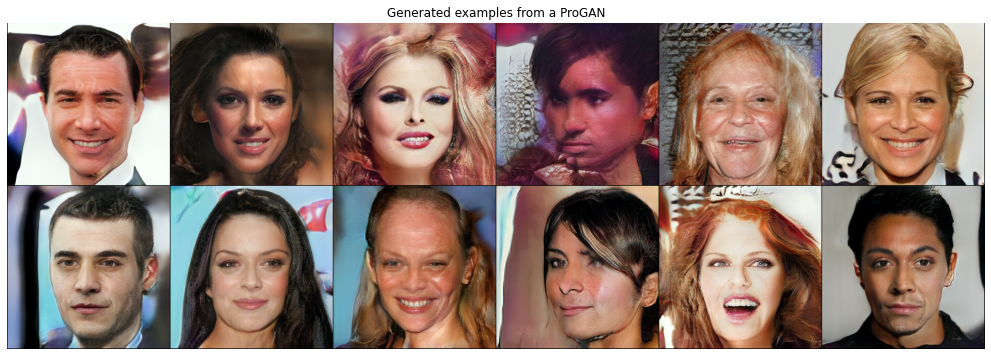

In [3]:
plot_progan(progan_model, num_images=12)

# StyleGAN

StyleGAN es una arquitectura GAN de 2018 que se basa en las ideas de ProGAN. De hecho, el discriminador es idéntico; sólo cambia el generador.

<div align="center">
    <img src="img/2018.png" alt="" width="70%" align="center" />
</div>

## Arquitectura general del generador StyleGAN

<div align="right">
    <img src="img/StyleGAN_generator.jpg" alt="" width="40%" align="right" />
</div>

En las GANs es difícil separar los vectores en el espacio latente correspondientes a atributos de alto nivel porque suelen estar entrelazados. Por lo tanto, al darle a una cara más pecas, podría cambiar también el color de fondo. 

StyleGAN logra controlar el estilo inyectando explícitamente vectores en diferentes puntos de la red, algunos que controlan características de alto nivel (por ejemplo, la orientación de la cara) y otros que controlan detalles de bajo nivel (por ejemplo, la forma en que el cabello cae sobre la frente).



### The Mapping Network

<div align="right">
    <img src="img/mapping_network.png" alt="" width="40%" align="right" />
</div>

La red de mapeo $f$ es una simple feed-forward que convierte el ruido de entrada $\mathbf{z} \in \mathcal{Z}$ en un espacio latente diferente $\mathbf{w} \in \mathcal{W}$. Esto le da al generador la oportunidad de desenredar el vector de entrada ruidoso en distintos factores de variación, que pueden ser fácilmente captados por las capas generadoras de estilo posteriores. El objetivo de hacer esto es separar el proceso de elegir un estilo para la imagen (la red de mapeo) de la generación de una imagen con un estilo determinado (la red de síntesis).

### The Synthesis Network

<div align="right">
    <img src="img/synthesis_network.png" alt="" width="40%" align="right" />
</div>

La red de síntesis es el generador de la imagen real con un estilo determinado, proporcionado por la red de mapeo. El vector de estilo $\mathbf{w}$ se inyecta en la red de síntesis en diferentes puntos, cada vez a través de una capa densamente conectada diferente ($A_i$), que genera dos vectores: un vector de sesgo $\mathbf{y}_{b,i}$ y un vector de escala $\mathbf{y}_{s,i}$. Estos vectores definen el estilo específico que se debe inyectar en este punto de la red; es decir, le dicen a la red de síntesis cómo ajustar los mapas de características para mover la imagen generada en la dirección del estilo especificado. Este ajuste se logra mediante capas de normalización de instancias adaptativas (AdaIN).

#### Adaptive instance normalization

<div align="right">
    <img src="img/AdaIN.png" alt="" width="40%" align="right" />
</div>

Las capas de normalización de instancias adaptables garantizan que los vectores de estilo que se inyectan en cada capa solo afecten a las características de esa capa, al evitar que cualquier información de estilo se filtre entre capas.

Los vectores de estilo en las capas anteriores de la red de síntesis (cuando la resolución de la imagen es más baja: 4 × 4, 8 × 8) afectarán a características más generales que las posteriores en la red (resolución de 64 × 64 a 1024 × 1024 píxeles). Esto significa que no solo tenemos control total sobre la imagen generada a través del vector latente $\mathbf{w}$, sino que también podemos cambiar el vector en diferentes puntos de la red de síntesis para cambiar el estilo en una variedad de niveles de detalle.


In [2]:
from stylegan import *

In [3]:
from collections import OrderedDict

# Modelo StyleGAN

- `stylegan_model.g_mapping`: red que transforma `z` → `w`

- `stylegan_model.g_synthesis`: red que genera la imagen desde `w` (modulado por capa)

In [4]:
stylegan_model = nn.Sequential(OrderedDict([
    ('g_mapping', G_mapping()),
    ('g_synthesis', G_synthesis())    
]))

In [5]:
stylegan_model.load_state_dict(torch.load('karras2019stylegan-ffhq-1024x1024.for_g_all.pt'));

In [6]:
device = 'cuda:0' if torch.cuda.is_available() else 'cpu'
stylegan_model.eval()
_ = stylegan_model.to(device)

In [7]:
torch.manual_seed(20);

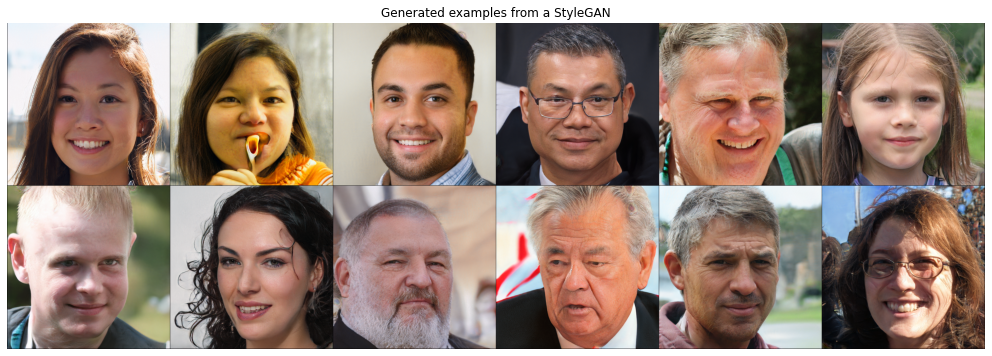

In [8]:
plot_stylegan(stylegan_model, device, num_images=12)

# Style mixing 🎭

En vez de usar un solo vector `w` para controlar todas las capas del generador (como harías normalmente), puedes usar dos (o más) vectores de estilo diferentes en distintas profundidades de la red para que cada uno influya sobre una parte distinta de la imagen. Entonces al mezclar estilos, estás literalmente **injertando rasgos** de una identidad a otra.

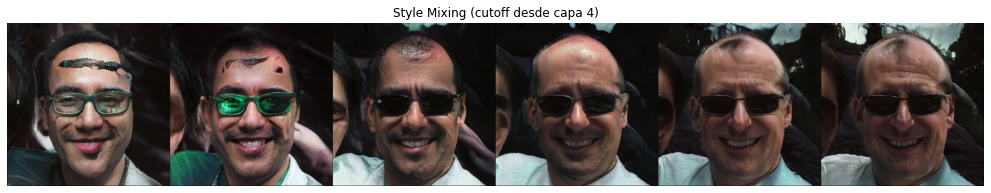

In [9]:
plot_style_mixing(stylegan_model, device, mixing_cutoff=4, num_images=6)

# El parámetro cutoff

Style mixing es como un “corte quirúrgico por capas” y el parámetro `cutoff` define en qué capa del generador se empieza a usar el segundo estilo (`w2`) en vez del primero (`w1`).

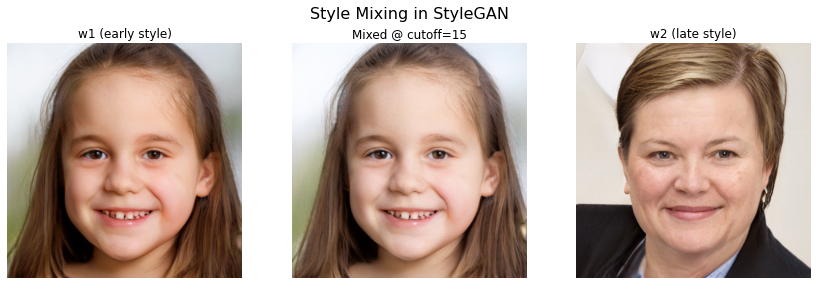

In [9]:
plot_style_mixing_with_refs(stylegan_model, device, cutoff=15, seed=42)

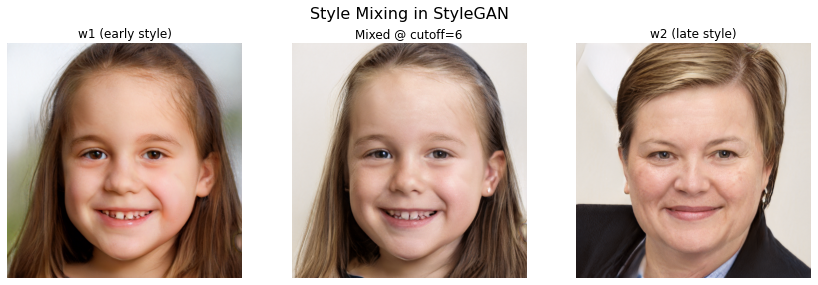

In [10]:
plot_style_mixing_with_refs(stylegan_model, device, cutoff=6, seed=42)

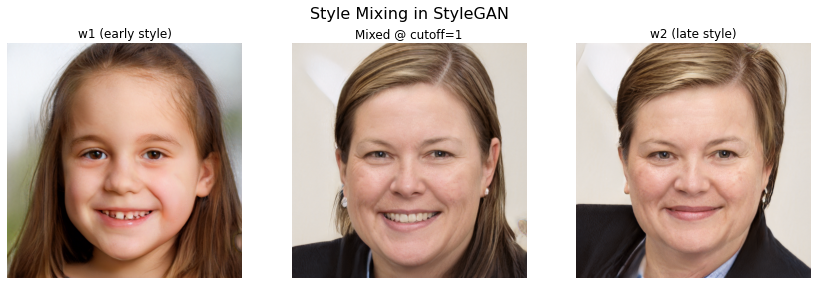

In [11]:
plot_style_mixing_with_refs(stylegan_model, device, cutoff=1, seed=42)

# Interpolation

La interpolación se utiliza para atravesar dos ubicaciones conocidas en el espacio latente y es una buena forma de demostrar que un modelo generativo no simplemente ha memorizado los ejemplos de entrenamiento.

<div align="center">
    <img src="img/latent_space.jpg" alt="" width="40%" align="center" />
</div>

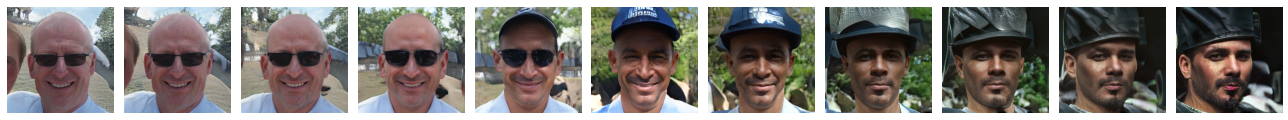

In [11]:
plot_interpolation(stylegan_model, device, nb_interp = 2)

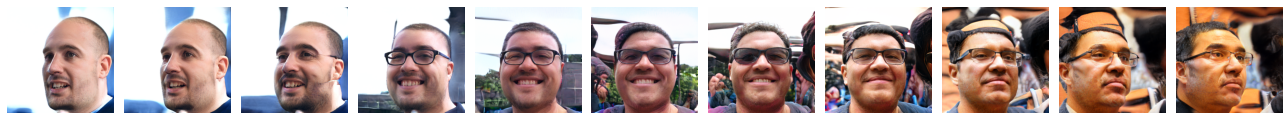

In [12]:
plot_interpolation(stylegan_model, device, nb_interp = 2)

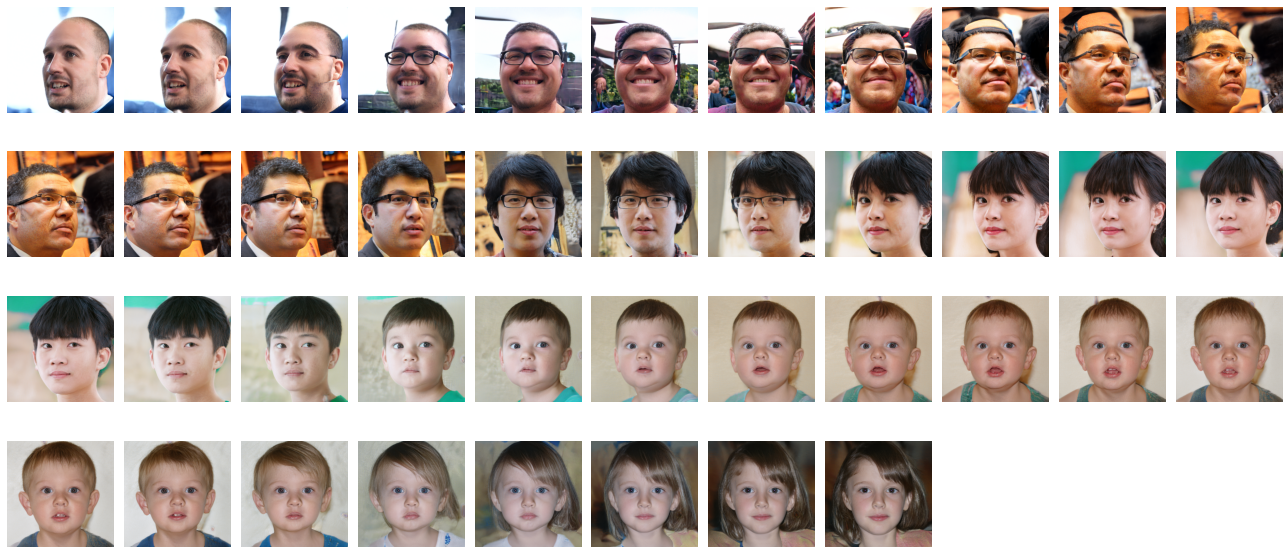

In [16]:
plot_interpolation(stylegan_model, device, nb_interp = 5)

# Self-Attention GAN (SAGAN)

El mecanismo de atención fue un desarrollo clave para las GAN, ya que incorpora el Transformer para la generación de imágenes. [Self-Attention GAN (SAGAN)](https://arxiv.org/pdf/1805.08318.pdf) en 2018 introduce el mecanismo de autoatención, que es una técnica utilizada en el campo del procesamiento del lenguaje natural (NLP) para capturar relaciones a larga distancia entre palabras en una oración. En el contexto de SAGAN, la autoatención se utiliza para capturar relaciones espaciales entre píxeles en una imagen. 

<div align="center">
    <img src="img/SAGAN.png" alt="" width="100%" align="center" />
</div>

## The self-attention mechanism within the SAGAN model

El mecanismo de autoatención permite que el modelo considere las relaciones entre diferentes partes de la imagen en lugar de depender únicamente de conexiones locales. Esto permite capturar características globales, como la relación entre partes distantes de una imagen, lo que mejora la coherencia y la calidad de las imágenes generadas.

<div align="center">
    <img src="img/attention_maps.png" alt="" width="100%" align="center" />
</div>

# BigGAN

[BigGAN](https://arxiv.org/pdf/1809.11096.pdf) (2019), desarrollado en DeepMind, logra SOTA en calidad (FID e IS) para datasets como ImageNet con modelos más grandes, batch size gigantesco, y uso de técnicas modernas como Class Conditional GANs, truncation trick, y Spectral Normalization.

<div align="center">
    <img src="img/biggan.png" alt="" width="10%" align="center" />
</div>

# Truncation Trick

Al entrenar una GAN, los vectores latentes `z` normalmente se muestrean de una distribución normal `z ~ N(0, 1)` pero algunos vectores aleatorios están muy lejos del promedio, lo que puede generar imágenes de baja calidad.

Entonces, en inferencia, el Truncation Trick consiste en **limitar la magnitud de los valores de `z`** a un determinado rango.

<div align="center">
    <img src="img/truncation_trick.png" alt="" width="20%" align="center" />
</div>

# Modelo BigGAN

In [ ]:
# pip install pytorch-pretrained-biggan

In [2]:
from pytorch_pretrained_biggan import BigGAN

In [3]:
biggan_model = BigGAN.from_pretrained('biggan-deep-256')

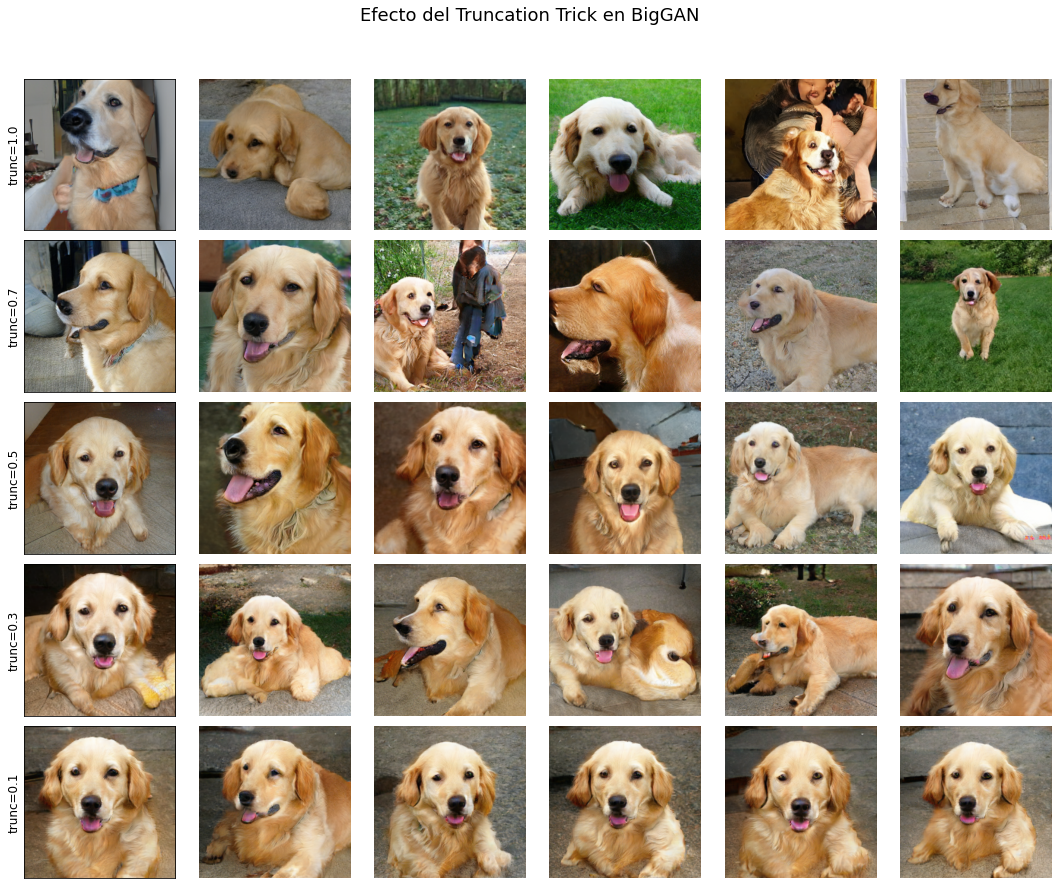

In [4]:
plot_truncation_effect_biggan(biggan_model, class_id=207, truncation_values=[1.0, 0.7, 0.5, 0.3, 0.1], num_cols=6)

In [5]:
data_dictionary =  transform_dict(load_data('imagenet1000_clsidx_to_labels.txt'))

In [6]:
print(list(data_dictionary.items())[:50])

[(0, ['tench', 'Tinca tinca']), (1, ['goldfish', 'Carassius auratus']), (2, ['great white shark', 'white shark', 'man-eater', 'man-eating shark', 'Carcharodon carcharias']), (3, ['tiger shark', 'Galeocerdo cuvieri']), (4, ['hammerhead', 'hammerhead shark']), (5, ['electric ray', 'crampfish', 'numbfish', 'torpedo']), (6, ['stingray']), (7, ['cock']), (8, ['hen']), (9, ['ostrich', 'Struthio camelus']), (10, ['brambling', 'Fringilla montifringilla']), (11, ['goldfinch', 'Carduelis carduelis']), (12, ['house finch', 'linnet', 'Carpodacus mexicanus']), (13, ['junco', 'snowbird']), (14, ['indigo bunting', 'indigo finch', 'indigo bird', 'Passerina cyanea']), (15, ['robin', 'American robin', 'Turdus migratorius']), (16, ['bulbul']), (17, ['jay']), (18, ['magpie']), (19, ['chickadee']), (20, ['water ouzel', 'dipper']), (21, ['kite']), (22, ['bald eagle', 'American eagle', 'Haliaeetus leucocephalus']), (23, ['vulture']), (24, ['great grey owl', 'great gray owl', 'Strix nebulosa']), (25, ['Europe

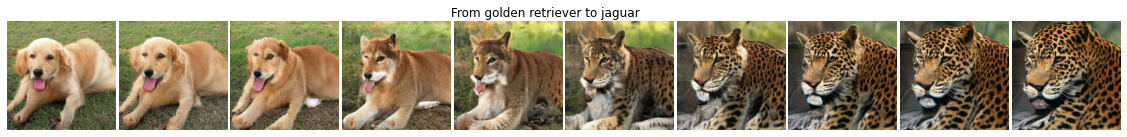

In [7]:
latent_walk(biggan_model, data_dictionary, "golden retriever", "jaguar", num_cols=10)

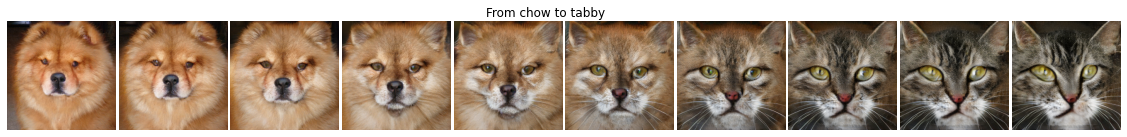

In [7]:
latent_walk(biggan_model, data_dictionary, "chow", "tabby", num_cols=10)

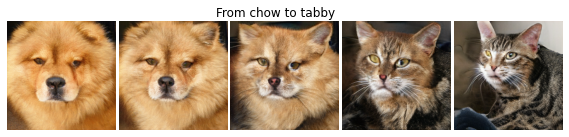

In [9]:
latent_walk(biggan_model, data_dictionary, "chow", "tabby", num_cols=5)